# 05 — Business Insights

This notebook consolidates funnel and conversion outputs into stakeholder-ready findings and prioritized opportunities.

## Coverage
- KPI summary
- Funnel drop-off and conversion opportunities
- Segment ranking
- Scenario analysis
- Executive visualizations
- Final metrics and recommendation exports

> Retailrocket provides no real order value or attribution metadata. `revenue` is a purchase indicator normalized to `1.00` and must not be interpreted as currency.

,stage,users,step_conversion,overall_conversion,drop_off_users
0,product_view,376,1.000000,1.000000,0
1,cart,199,0.529255,0.529255,177
2,purchase,22,0.110553,0.058511,177


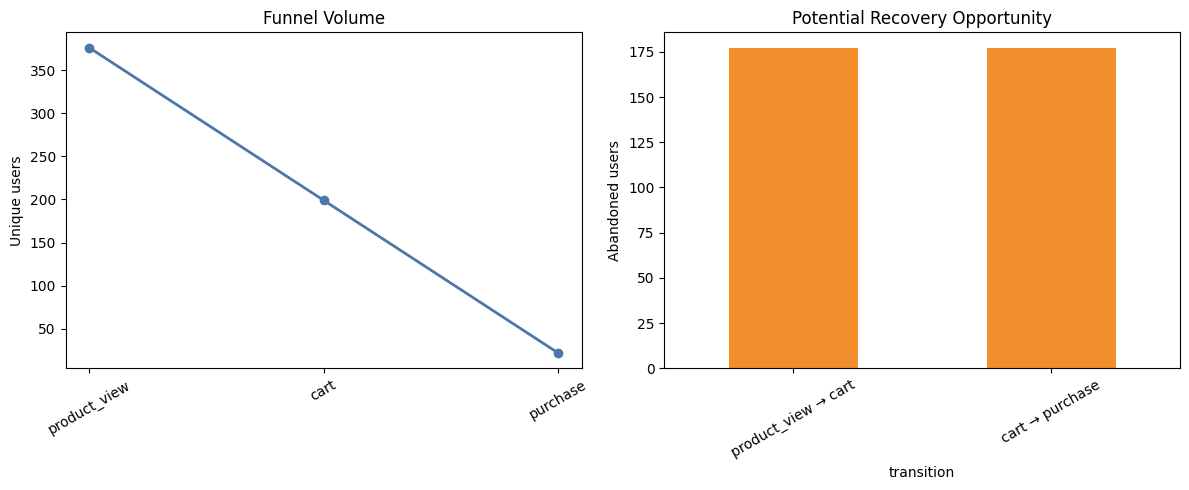

,kpi,value
0,product_view_users,376.000000
1,cart_users,199.000000
2,purchase_users,22.000000
3,product_view_to_purchase_rate,0.058511


,transition,abandoned_users,normalized_indicator_value_per_user,estimated_recovery_indicator
0,product_view → cart,177,201.3,35629.46
1,cart → purchase,177,201.3,35629.46


,priority,area,recommendation,primary_metric
0,1,Largest funnel drop-off,"Diagnose friction, relevance, and tracking at ...",step conversion rate
1,2,Cart completion,Test cart reminders or a simplified return-to-...,cart-to-purchase conversion
2,3,Measurement,Replace normalized revenue and unknown attribu...,data completeness and incrementality


Figures and tables exported to: /home/essie/e-commerce-conversion-customer-funnel-analysis/reports


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

DATA_PATH = ROOT / "data" / "processed" / "ecommerce_funnel_events_clean.csv"
if not DATA_PATH.exists():
    raise FileNotFoundError("Run the real-data pipeline first")

df = pd.read_csv(DATA_PATH)
STAGES = ["product_view", "cart", "purchase"]
counts = df.groupby("stage")["user_id"].nunique().reindex(STAGES)

funnel = pd.DataFrame({"stage": STAGES, "users": [int(counts[s]) for s in STAGES]})
funnel["step_conversion"] = funnel["users"].div(funnel["users"].shift(1)).fillna(1.0)
funnel["overall_conversion"] = funnel["users"] / funnel["users"].iloc[0]

display(funnel)

kpis = pd.DataFrame([
    {"kpi": "product_view_users", "value": int(counts["product_view"])},
    {"kpi": "cart_users", "value": int(counts["cart"])},
    {"kpi": "purchase_users", "value": int(counts["purchase"])},
    {"kpi": "product_view_to_purchase_rate", "value": int(counts["purchase"]) / int(counts["product_view"])},
])
display(kpis)

kpis.to_csv(ROOT / "reports" / "business_kpis.csv", index=False)
funnel.to_csv(ROOT / "reports" / "business_funnel_metrics.csv", index=False)
